# 01 · Explore Part D 2019 + LEIE
Goal: understand the two raw sources, join them on NPI, and count how many positive labels we actually have.
See `data-notes.md` for the summary of counts and quirks.

In [21]:
import duckdb
import matplotlib.pyplot as plt

# The notebook runs from notebooks/, so paths start with ../
con = duckdb.connect("../data/screener.duckdb")

# Load the raw CSVs only the first time; later runs reuse the tables saved in the database file
con.sql("CREATE TABLE IF NOT EXISTS partd_2019 AS SELECT * FROM read_csv('../data/raw/partd_2019.csv')")
con.sql("CREATE TABLE IF NOT EXISTS leie AS SELECT * FROM read_csv('../data/raw/leie.csv')")

con.sql("SELECT COUNT(*) AS n_rows FROM partd_2019").show()
con.sql("SELECT COUNT(*) AS n_rows FROM leie").show()

┌─────────┐
│ n_rows  │
│  int64  │
├─────────┤
│ 1240595 │
└─────────┘

┌────────┐
│ n_rows │
│ int64  │
├────────┤
│  84224 │
└────────┘



## 1. What the tables look like

In [22]:
con.sql("DESCRIBE partd_2019").show()

┌───────────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│      column_name      │ column_type │  null   │   key   │ default │  extra  │
│        varchar        │   varchar   │ varchar │ varchar │ varchar │ varchar │
├───────────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ Prscrbr_NPI           │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ Prscrbr_Last_Org_Name │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ Prscrbr_First_Name    │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ Prscrbr_MI            │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ Prscrbr_Crdntls       │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ Prscrbr_Ent_Cd        │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ Prscrbr_St1           │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ Prscrbr_St2           │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ Prscrbr_City          │ VARCHAR     │ 

In [23]:
con.sql("DESCRIBE leie").show()

┌─────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│ column_name │ column_type │  null   │   key   │ default │  extra  │
│   varchar   │   varchar   │ varchar │ varchar │ varchar │ varchar │
├─────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ LASTNAME    │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ FIRSTNAME   │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ MIDNAME     │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ BUSNAME     │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ GENERAL     │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ SPECIALTY   │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ UPIN        │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ NPI         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ DOB         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ ADDRESS     │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ CITY        │ VARC

`partd_2019` has 84 columns and `leie` has 18. The NPI is `Prscrbr_NPI` in Part D and `NPI` in the LEIE; both are BIGINT, so they join directly.
NPIs never start with 0, so storing them as numbers is safe. But `ZIP` is also BIGINT and loses leading zeros (02139 → 2139): IDs and codes should be stored as text.

In [24]:
con.sql("SELECT COUNT(*) FROM partd_2019").show()
con.sql("SELECT COUNT(DISTINCT Prscrbr_NPI) FROM partd_2019").show()

┌──────────────┐
│ count_star() │
│    int64     │
├──────────────┤
│      1240595 │
└──────────────┘

┌─────────────────────────────┐
│ count(DISTINCT Prscrbr_NPI) │
│            int64            │
├─────────────────────────────┤
│                     1240595 │
└─────────────────────────────┘



One row per prescriber: 1,240,595 rows and 1,240,595 distinct NPIs.

## 2. LEIE quirks

In [25]:
con.sql("SELECT * FROM leie LIMIT 10")

LASTNAMEVARCHAR,FIRSTNAMEVARCHAR,MIDNAMEVARCHAR,BUSNAMEVARCHAR,GENERALVARCHAR,SPECIALTYVARCHAR,UPINVARCHAR,NPIBIGINT,DOBBIGINT,ADDRESSVARCHAR,CITYVARCHAR,STATEVARCHAR,ZIPBIGINT,EXCLTYPEVARCHAR,EXCLDATEBIGINT,REINDATEBIGINT,WAIVERDATEBIGINT,WVRSTATEVARCHAR
NULL,NULL,NULL,"#1 MARKETING SERVICE, INC",OTHER BUSINESS,SOBER HOME,NULL,0,NULL,239 BRIGHTON BEACH AVENUE,BROOKLYN,NY,11235,1128a1,20200319,0,0,NULL
NULL,NULL,NULL,"1 BEST CARE, INC",OTHER BUSINESS,HOME HEALTH AGENCY,NULL,0,NULL,"2161 UNIVERSITY AVENUE W, STE",SAINT PAUL,MN,55114,1128b5,20230518,0,0,NULL
NULL,NULL,NULL,101 FIRST CARE PHARMACY INC,OTHER BUSINESS,PHARMACY,NULL,1972902351,NULL,"C/O 609 W 191ST STREET, APT D",NEW YORK,NY,10040,1128b8,20220320,0,0,NULL
NULL,NULL,NULL,14 LAWRENCE AVE PHARMACY,PHARMACY,NULL,NULL,0,NULL,14 LAWRENCE AVENUE,SMITHTOWN,NY,11787,1128a1,19880830,0,0,NULL
NULL,NULL,NULL,143 MEDICAL EQUIPMENT CO,DME COMPANY,DME - OXYGEN,NULL,0,NULL,701 NW 36 AVENUE,MIAMI,FL,33125,1128b7,19970620,0,0,NULL
NULL,NULL,NULL,"149 BALLSTON AVENUE, LLC",OTHER BUSINESS,MARKETING FIRM,NULL,0,NULL,"C/O 365 W END AVE, APT 5A",NEW YORK,NY,10024,1128b6,20230227,0,0,NULL
NULL,NULL,NULL,184TH STREET PHARMACY CORP,OTHER BUSINESS,PHARMACY,NULL,1922348218,NULL,69 E 184TH ST,BRONX,NY,10468,1128a1,20180419,0,0,NULL
NULL,NULL,NULL,1951 FLATBUSH AVENUE PHARMACY,PHARMACY,NULL,NULL,0,NULL,1951 FLATBUSH AVE,BROOKLYN,NY,11234,1128b5,20090319,0,0,NULL
NULL,NULL,NULL,"1ST COMMUNITY HEALTH CTR, LTD",CLINIC,NULL,NULL,0,NULL,3138 W CERMAK ROAD,CHICAGO,IL,60623,1128a1,19940524,0,0,NULL
NULL,NULL,NULL,1ST REHABILITATION OF PORT ST,MANAGEMENT SVCS CO,NULL,NULL,0,NULL,C/O 3659 MAGUIRE BLVD,ORLANDO,FL,32803,1128b8,20020919,0,0,NULL


Many rows have `NPI = 0`, meaning no NPI was recorded. Several of these are businesses (a marketing firm, pharmacies, a home health agency), not prescribers.

In [26]:
con.sql("SELECT COUNT(*) AS n_real FROM leie WHERE NPI != 0").show()
con.sql("SELECT COUNT(*) AS n_not_real FROM leie WHERE NPI = 0").show()

┌────────┐
│ n_real │
│ int64  │
├────────┤
│   9023 │
└────────┘

┌────────────┐
│ n_not_real │
│   int64    │
├────────────┤
│      75201 │
└────────────┘



Only **9,023 of 84,224** LEIE rows (10.7%) have a real NPI; 75,201 have `NPI = 0`.
Only rows with a real NPI can ever be matched to Part D, so at most ~9,000 exclusions are usable as labels.

In [27]:
con.sql("""
    SELECT MIN(REINDATE) AS min_reindate,
           MAX(REINDATE) AS max_reindate
    FROM leie
""").show()

┌──────────────┬──────────────┐
│ min_reindate │ max_reindate │
│    int64     │    int64     │
├──────────────┼──────────────┤
│            0 │            0 │
└──────────────┴──────────────┘



`EXCLDATE` is a date stored as a YYYYMMDD number (e.g. `20200319`). It sorts like a date, so comparisons work, but it needs converting for date arithmetic (Day 9).

`REINDATE` is 0 in every row: the full LEIE file only lists providers who are excluded **right now**, and reinstated providers are removed.
So our labels miss everyone who was excluded and later reinstated (**label bias**).

In [28]:
con.sql("SELECT EXCLTYPE, COUNT(*) AS n FROM leie GROUP BY EXCLTYPE ORDER BY COUNT(*) DESC").show()

┌──────────┬───────┐
│ EXCLTYPE │   n   │
│ varchar  │ int64 │
├──────────┼───────┤
│ 1128b4   │ 33463 │
│ 1128a1   │ 26104 │
│ 1128a2   │  8127 │
│ 1128a3   │  5884 │
│ 1128a4   │  3592 │
│ 1128b14  │  2164 │
│ 1128b8   │  1497 │
│ 1128b1   │   943 │
│ 1128b5   │   879 │
│ 1128b7   │   766 │
│ 1128b3   │   329 │
│ 1128Aa   │   178 │
│ 1128b6   │    77 │
│ 1128b2   │    65 │
│ 1156     │    53 │
│ 1128b15  │    37 │
│ BRCH SA  │    28 │
│ BRCH CIA │    14 │
│ 1128b11  │    13 │
│ 1160     │     8 │
│ 1128b16  │     2 │
│ 1128b12  │     1 │
└──────────┴───────┘
      22 rows     



22 exclusion types. The most common, `1128b4` (license revoked or suspended), is often not about fraud; `1128a1` (conviction for a Medicare/Medicaid-related crime) is second.
Which codes count as positive is a design decision (section 3).

In [29]:
con.sql("SELECT * FROM partd_2019 LIMIT 10").show()

┌─────────────┬───────────────────────┬────────────────────┬────────────┬─────────────────┬────────────────┬─────────────────────────┬─────────────┬──────────────┬──────────────────────┬────────────────────┬──────────────┬──────────────┬─────────────────────────────────────────────────────────────────────────────────────┬───────────────┬─────────────────────┬──────────────────┬──────────┬────────────────────┬────────────────────┬───────────────┬───────────┬─────────────────┬───────────────┬──────────────────────┬────────────────────┬────────────────────┬──────────────────────┬────────────────┬─────────────────┬───────────────┬────────────────────┬─────────────────┬───────────────┬────────────────────┬─────────────────┬───────────────┬───────────────────┬─────────────────┬───────────────┬────────────────────┬────────────────┬──────────────┬────────────────────┬────────────────┬──────────────┬────────────────────┬───────────────────┬─────────────────┬────────────────────┬────────────────

In [30]:
con.sql("SELECT Prscrbr_Type, COUNT(*) AS n FROM partd_2019 GROUP BY Prscrbr_Type ORDER BY COUNT(*) DESC LIMIT 10").show()

┌────────────────────────────────────────────────────────────────┬────────┐
│                          Prscrbr_Type                          │   n    │
│                            varchar                             │ int64  │
├────────────────────────────────────────────────────────────────┼────────┤
│ Nurse Practitioner                                             │ 187939 │
│ Dentist                                                        │ 131165 │
│ Internal Medicine                                              │ 125856 │
│ Family Practice                                                │ 112025 │
│ Physician Assistant                                            │ 103945 │
│ Student in an Organized Health Care Education/Training Program │  58640 │
│ Emergency Medicine                                             │  50364 │
│ Obstetrics & Gynecology                                        │  35242 │
│ Optometry                                                      │  30875 │
│ Psychiatry

Nurse practitioners are the largest group, and dentists are #2, so comparing prescribers only within their own specialty will be essential.
There's also a 58,640-row category for residents ("Student in an Organized Health Care Education/Training Program").

## 3. Real NPIs: how old are the exclusions, and which types?

In [31]:
con.sql("""
    SELECT
        CASE WHEN NPI = 0 THEN 'no_npi' ELSE 'real_npi' END AS npi_type,
        COUNT(*)          AS n,
        MIN(EXCLDATE)     AS first_excl,
        MEDIAN(EXCLDATE)  AS median_excl,
        MAX(EXCLDATE)     AS last_excl
    FROM leie
    GROUP BY 1
""").show()

┌──────────┬───────┬────────────┬─────────────┬───────────┐
│ npi_type │   n   │ first_excl │ median_excl │ last_excl │
│ varchar  │ int64 │   int64    │   double    │   int64   │
├──────────┼───────┼────────────┼─────────────┼───────────┤
│ real_npi │  9023 │   19880703 │  20190820.0 │  20261119 │
│ no_npi   │ 75201 │   19770701 │  20081020.0 │  20261119 │
└──────────┴───────┴────────────┴─────────────┴───────────┘



Rows without an NPI are typically much older (median exclusion Oct 2008 vs Aug 2019 for real NPIs), consistent with NPIs being issued from 2005 and required from 2007.
But no-NPI exclusions are still being added today (latest Nov 2026), likely businesses and workers who never bill as prescribers. Either way, none of them can be matched to Part D.

**Positive definition (first draft, to finalize on Day 6):** fraud- and drug-related exclusions:
`1128a1`, `1128a3`, `1128a4`, `1128b1`, `1128b3`, `1128b7`.
`1128b4` (license revoked) is a "maybe": the biggest group, sometimes caused by misconduct such as overprescribing, but often unrelated to fraud.
The table below includes it so we can see how much it would add.

In [32]:
con.sql("""
    SELECT EXCLTYPE, COUNT(*) AS n
    FROM leie
    WHERE NPI != 0
      AND EXCLTYPE IN ('1128a1', '1128a3', '1128a4', '1128b1', '1128b3', '1128b7', '1128b4')
    GROUP BY EXCLTYPE
    ORDER BY n DESC
""").show()

┌──────────┬───────┐
│ EXCLTYPE │   n   │
│ varchar  │ int64 │
├──────────┼───────┤
│ 1128a1   │  3413 │
│ 1128b4   │  2691 │
│ 1128a4   │  1019 │
│ 1128a3   │   684 │
│ 1128b7   │   208 │
│ 1128b1   │    48 │
│ 1128b3   │    20 │
└──────────┴───────┘



In [33]:
# Total for the six positive codes (no GROUP BY -> one total)
con.sql("""
    SELECT COUNT(*) AS n_six_codes
    FROM leie
    WHERE NPI != 0
      AND EXCLTYPE IN ('1128a1', '1128a3', '1128a4', '1128b1', '1128b3', '1128b7')
""").show()

# The same, with the 1128b4 "maybe" added
con.sql("""
    SELECT COUNT(*) AS n_with_b4
    FROM leie
    WHERE NPI != 0
      AND EXCLTYPE IN ('1128a1', '1128a3', '1128a4', '1128b1', '1128b3', '1128b7', '1128b4')
""").show()

┌─────────────┐
│ n_six_codes │
│    int64    │
├─────────────┤
│        5392 │
└─────────────┘

┌───────────┐
│ n_with_b4 │
│   int64   │
├───────────┤
│      8083 │
└───────────┘



Real-NPI rows: **5,392** with the six codes; **8,083** with `1128b4` added (+2,691, +50%).
These are all-time counts (1988–2026). Only exclusions in the label window will become positives (section 4).

## 4. Joining the LEIE to Part D 2019

In [34]:
con.sql("""
    SELECT COUNT(*) AS n, COUNT(DISTINCT l.NPI) AS n_distinct
    FROM leie AS l
      INNER JOIN partd_2019 AS p
        ON l.NPI = p.Prscrbr_NPI
""").show()

┌───────┬────────────┐
│   n   │ n_distinct │
│ int64 │   int64    │
├───────┼────────────┤
│  1475 │       1453 │
└───────┴────────────┘



1,475 LEIE rows (any code) match a 2019 prescriber, but only 1,453 distinct NPIs: **22 NPIs have more than one LEIE row**.
When building labels, use distinct NPIs, or the join will duplicate prescribers (fan-out).

In [35]:
con.sql("""
    SELECT COUNT(*) AS n, COUNT(DISTINCT l.NPI) AS n_distinct
    FROM leie AS l
      INNER JOIN partd_2019 AS p
        ON l.NPI = p.Prscrbr_NPI
    WHERE l.EXCLTYPE IN ('1128a1', '1128a3', '1128a4', '1128b1', '1128b3', '1128b7')
""").show()

┌───────┬────────────┐
│   n   │ n_distinct │
│ int64 │   int64    │
├───────┼────────────┤
│   916 │        913 │
└───────┴────────────┘



With the six codes: 916 matched rows, 915 distinct NPIs (with `1128b4` added: 1,404 rows, 1,391 NPIs).

### When were the matched prescribers excluded, relative to the 2019 feature year?

In [36]:
con.sql("""
    SELECT
        CASE
            WHEN l.EXCLDATE < 20190101                      THEN 'before_2019'
            WHEN l.EXCLDATE BETWEEN 20190101 AND 20191231   THEN 'during_2019'
            WHEN l.EXCLDATE BETWEEN 20200101 AND 20211231   THEN 'label_window_2020_2021'
            WHEN l.EXCLDATE > 20211231                      THEN 'after_2021'
            ELSE 'invalid'
        END                    AS time_period,
        COUNT(*)               AS n,
        COUNT(DISTINCT l.NPI)  AS n_distinct
    FROM leie AS l
      INNER JOIN partd_2019 AS p
        ON l.NPI = p.Prscrbr_NPI
    WHERE l.EXCLTYPE IN ('1128a1', '1128a3', '1128a4', '1128b1', '1128b3', '1128b7')
    GROUP BY 1
    ORDER BY n DESC
""").show()

┌────────────────────────┬───────┬────────────┐
│      time_period       │   n   │ n_distinct │
│        varchar         │ int64 │   int64    │
├────────────────────────┼───────┼────────────┤
│ after_2021             │   724 │        723 │
│ label_window_2020_2021 │   151 │        151 │
│ during_2019            │    39 │         39 │
│ before_2019            │     2 │          2 │
└────────────────────────┴───────┴────────────┘



With the six codes:
- **`label_window_2020_2021`: 151 prescribers. These are the positives** for 2019 features (label = excluded within 2 years).
- `during_2019` (39) and `before_2019` (2): already excluded by the end of the feature year → **drop** them (neither positive nor negative).
- `after_2021` (724): excluded later than the 2-year window, so they count as **negatives** for 2019 features. That's the cost of choosing H = 2; revisit on Day 9.

`before_2019` puzzle: excluded providers can't bill Medicare, yet these 2 have 2019 prescriptions.
**My guess:** TODO (hint: check their `WAIVERDATE`).

In [37]:
# Same breakdown with the 1128b4 "maybe" included
con.sql("""
    SELECT
        CASE
            WHEN l.EXCLDATE < 20190101                      THEN 'before_2019'
            WHEN l.EXCLDATE BETWEEN 20190101 AND 20191231   THEN 'during_2019'
            WHEN l.EXCLDATE BETWEEN 20200101 AND 20211231   THEN 'label_window_2020_2021'
            WHEN l.EXCLDATE > 20211231                      THEN 'after_2021'
            ELSE 'invalid'
        END                    AS time_period,
        COUNT(*)               AS n,
        COUNT(DISTINCT l.NPI)  AS n_distinct
    FROM leie AS l
      INNER JOIN partd_2019 AS p
        ON l.NPI = p.Prscrbr_NPI
    WHERE l.EXCLTYPE IN ('1128a1', '1128a3', '1128a4', '1128b1', '1128b3', '1128b7', '1128b4')
    GROUP BY 1
    ORDER BY n DESC
""").show()

┌────────────────────────┬───────┬────────────┐
│      time_period       │   n   │ n_distinct │
│        varchar         │ int64 │   int64    │
├────────────────────────┼───────┼────────────┤
│ after_2021             │  1164 │       1159 │
│ label_window_2020_2021 │   193 │        193 │
│ during_2019            │    45 │         45 │
│ before_2019            │     2 │          2 │
└────────────────────────┴───────┴────────────┘



With `1128b4` included: **193** positives in the label window (+42 over the six codes).

## 5. Class imbalance

In [38]:
# LEFT JOIN keeps all 1.24M prescribers; those with no match in `positives` get NULL -> 'negative'.
# NPI = 0 never matches a prescriber, so it needs no filter here.
labels = con.sql("""
    WITH positives AS (
        SELECT DISTINCT NPI          -- DISTINCT avoids the duplicate-NPI fan-out
        FROM leie
        WHERE EXCLTYPE IN ('1128a1', '1128a3', '1128a4', '1128b1', '1128b3', '1128b7')
          AND EXCLDATE BETWEEN 20200101 AND 20211231
    )
    SELECT
        CASE WHEN pos.NPI IS NULL THEN 'negative' ELSE 'positive' END AS label,
        COUNT(*) AS n
    FROM partd_2019 AS p
      LEFT JOIN positives AS pos
        ON p.Prscrbr_NPI = pos.NPI
    GROUP BY 1
    ORDER BY n DESC
""").df()

labels["pct"] = 100 * labels["n"] / labels["n"].sum()
labels

,label,n,pct
0,negative,1240444,99.987828
1,positive,151,0.012172


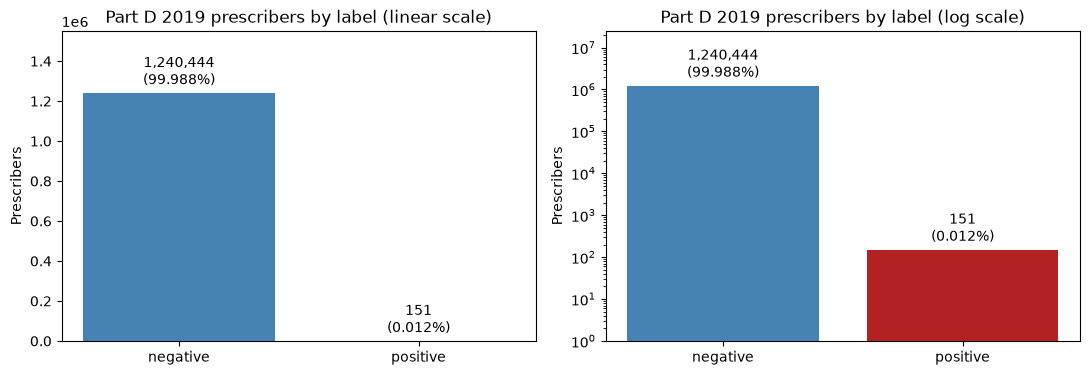

In [39]:
# fig = the whole image; each ax = one chart inside it.
# plt.subplots(1, 2) -> 1 row with 2 charts, returned as an array: axes[0], axes[1]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
bar_text = [f"{n:,}\n({p:.3f}%)" for n, p in zip(labels["n"], labels["pct"])]

for ax, scale in zip(axes, ["linear", "log"]):
    bars = ax.bar(labels["label"], labels["n"], color=["steelblue", "firebrick"])
    ax.set_yscale(scale)
    ax.set(title=f"Part D 2019 prescribers by label ({scale} scale)", ylabel="Prescribers")
    ax.bar_label(bars, labels=bar_text, padding=3)

axes[0].set_ylim(0, labels["n"].max() * 1.25)   # room for the labels above the bars
axes[1].set_ylim(1, labels["n"].max() * 20)     # log scale can't start at 0

plt.tight_layout()
plt.show()

**151 positives out of 1,240,595 prescribers: 0.012%, about 1 in 8,200.** On a linear scale the positive bar is invisible.
A model that always says "negative" would be 99.99% accurate, which is why the project uses **precision@500**, not accuracy.
